# <div align="center">  Assignment 1: Power Spectral Density Estimation </div>

## <div align="center"> Deadline: See Module’s Brightspace </div>

**Note:** This assignment is worth **15%** towards the total module grade.

# Description
You are given an audio file that contains a chord (played three times) recorded from a piano. A chord, in any musical instrument, consists of two or more (usually three or more) notes (also called “pitches”) that are heard as if sounding simultaneously. Some background on piano notes is given in the Appendix at the end of the file. Your task is to detect all the notes in the given chord. To do this, a possible method is to estimate the power spectral density (PSD) of the signal.

# Read in data
Download the audio file provided in the Brighspce portal for this assignment (i.e. the "PianoChord.wav"). You can play this audio file using any media player available to you to hear the chord. To read the audio file in Python, you can use the following code

In [143]:
from scipy.io import wavfile
Fs, data = wavfile.read('PianoChord.wav')
print("The sampling rate is %f" %Fs) # print out the sampling rate of the audio file

The sampling rate is 48000.000000


/tmp/ipykernel_66130/1046975494.py:2: WavFileWarning: Chunk (non-data) not understood, skipping it.
  Fs, data = wavfile.read('PianoChord.wav')


The following code cell plots the waveform (i.e. the time domain representation) of the sound.

The number of samples N is  96000


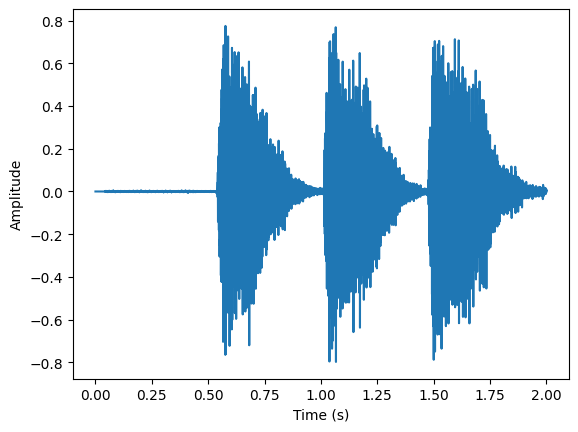

In [144]:
import matplotlib.pyplot as plt
import numpy as np
N = data.size ## number of samples
print("The number of samples N is ", N)
plt.plot(np.arange(N)/Fs, data)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

# TASK 1: Periodogram
Write a Python program to compute and plot the periodogram to estimate the PSD of the given  signal and give your comments. Make your observations based on the obtained periodogram

## Task 1 Answer (1/3) Periodogram
The periodogram estimates the PSD by the following equation:
$ S_X(e^{i\omega}) \approx \hat{S}^{P}_{X}(e^{j\omega}) = \frac{1}{N}|\sum_{n=0}^{N-1}{x(n)e^{(-jn\omega)}}|^2 = \frac{1}{N}|X(e^{j\omega})|^2$

The PSD presented in the lectures and tutorials uses the **normalised angular frequency** (in the $-\pi$ to $\pi$ range).

Since I end up plotting the PSD for frequencies 0-24kHz, I divide the resulting PSD estimates by Fs, which means I'm plotting (dB/Hz). The easiest way to understand why I did this is to observe the following relationship:

Normalised by angular frequency:
$P = \frac{1}{2\pi}\int_{-\pi}^{\pi}S_x(e^{j\omega})d\omega$

So to estimate the PSD given data, we can follow the following pseudo-code:
```
X = DFT(data) // get the DFT 
X_mag = abs(X) // get its magnitude
S_xx = (1/N) * (X_mag**2) // following the above equation, the PSD can be estimated by 1/N * |X|^2
```

Since the input data contains only real values, the output of the DFT is Hermitian-symmetric. This means that the negative frequency terms are conjugates of the positive frequency terms, so they are the same and thus redundant.

We can therefore use numpy's fft.rfft, which computes the DFT for a real input of size N and returns an complex array of size N//2 + 1  (only positive frequencies). This is twice as fast and it computes twice less values.

Lastly, we note the frequency per bin in the returned array is Fs/N. In this case we have 48000 / 96000 = 0.5Hz per bin.

When plotting the resulting estimated PSD we can set the frequency of each bin to i*(Fs/N)


https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html

In [153]:
X = np.fft.rfft(data) # Obtain the DFT of x

X_mag = np.abs(X) # Obtain the magnitude of each frequency bin. Since the result of fft is complex.

S_xx = (1/N) * (X_mag**2) # Periodogram formula 
# freqs = (Fs/N)*np.arange(N//2 + 1)
freqs = np.fft.rfftfreq(N, d=1/Fs)

# plt.plot(freqs/1000, S_xx)
# plt.xlabel('Frequency (kHz)')
# plt.ylabel('Amplitude')
# plt.show()

The relevant information is in the <5kHz range.
Let's re-plot 

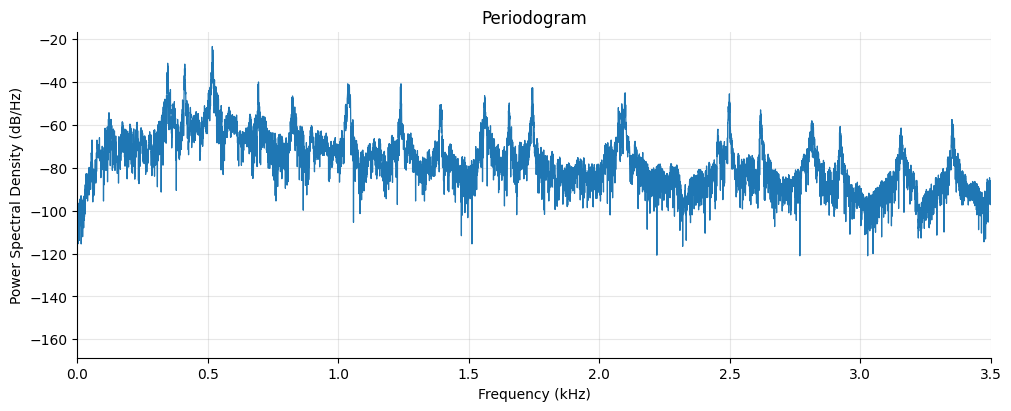

In [154]:

# plt.semilogy(freqs, S_xx)
# plt.xlim(0,3500)
# plt.xlabel('Frequency (kHz)')
# plt.ylabel('Amplitude (dB)')
# plt.show()

# X = np.fft.rfft(data)
# freqs = np.fft.rfftfreq(N, d=1/Fs)
# S_xx = np.abs(X)**2 / N
S_xx /= Fs
S_xx_dB = 10 * np.log10(np.maximum(S_xx, np.finfo(float).tiny))

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)

ax.plot(freqs / 1000, S_xx_dB, linewidth=0.9)
ax.set(
    xlim=(0, 3.5),
    xlabel="Frequency (kHz)",
    ylabel="Power Spectral Density (dB/Hz)",
    title="Periodogram"
)
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.show()

In [155]:
# The peaks across this 
from scipy.signal import find_peaks

peaks, i = find_peaks(S_xx, prominence=0.01*S_xx.max(), distance=70)
strongest = peaks[np.argsort(S_xx[peaks])[-5:]]

print("The peaks with the highest power are at:")
for p in strongest:
    print(f"{freqs[p]:.2f} Hz: {S_xx_dB[p]:.2f} dB")
# for 

The peaks with the highest power are at:
1240.00 Hz: -40.77 dB
694.00 Hz: -39.93 dB
411.50 Hz: -31.58 dB
346.00 Hz: -31.18 dB
517.00 Hz: -23.35 dB


## Task 1 Answer (3/3) Observations

The periodogram approximates the PSD well enough that we can already begin to see the original chord.

Out of the 5 peaks with the highest power we have:

**Fundamentals:**
* f2 C5  523.2511Hz
* f1 G#4	415.3047Hz
* f0 F4	349.2282Hz

**Harmonics:**
* 2*f0 ~= 694Hz
* 3*f1 ~= 1240Hz

A more detailed analysis of the harmonics will follow in Task 2.


# TASK 2: Welch's method
Write a Python program that implements Welch’s method to estimate the PSD of the given chord and identify all the notes present in the signal. Plot the estimated PSD and compare it with the estimated PSD obtained in Task 1. In your implementation, address the following requirements
1. Provide an explanation on a proper choice for the size of the FFT for each segment, considering the frequency resolution required to distinguish the musical notes.
2. Ensure that all samples of the signal are included in the PSD estimation.
3. Investigate and discuss the impact of changing the number of samples per segment and the amount of overlapping on the performance.

In [148]:
# Welch's method
# overlapping K sectiosn of length L
# each section multiplied by a hanning window

L = int(8192)
window = np.hanning(L)
U = np.mean(window**2)
k = int(0)
S_xx_Welch = np.zeros(L//2 + 1)
nSegments = 0
while k < N:
    if (k >= N-L):
        current_segment = np.concatenate((data[int(k):int(N)], np.zeros(k-(N-L)))) * window
    else:
        current_segment = data[int(k):int(k+L)] * window

    current_segment_fft = np.fft.rfft(current_segment)
    current_segment_fft_mag = np.abs(current_segment_fft)
    current_segment_periodogram = (current_segment_fft_mag**2)
    S_xx_Welch += current_segment_periodogram # accumulate the periodogram
    nSegments += 1
    k += L//2 # Move to the next overlapping segment (overlapping by 50%)

S_xx_Welch /= (nSegments*L*U) # Normalise the PSD.
freqs_welch = Fs/L * np.arange(L//2 + 1)

The peaks with the highest power are at:
3351.56 Hz, -16.35 dB
2496.09 Hz, -5.69 dB
1746.09 Hz, -4.16 dB
1037.11 Hz, 1.66 dB
515.62 Hz, 15.07 dB


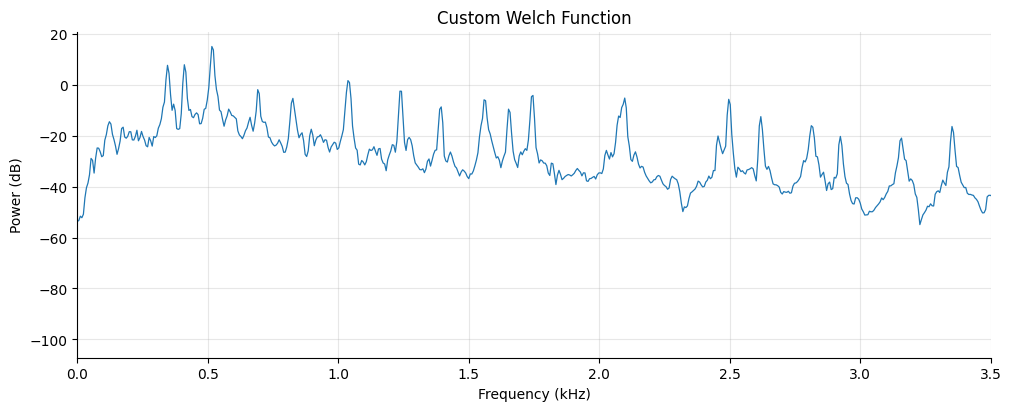

In [149]:
# peaks = np.where(
#     (S_xx_Welch[1:-1] > S_xx_Welch[:-2]) &
#     (S_xx_Welch[1:-1] > S_xx_Welch[2:])
# )[0] + 1

# # Inspect the low-frequency region
# peaks = peaks[(freqs_welch[peaks] >= 50) & (freqs_welch[peaks] <= 5000)]
# print(list(freqs_welch[p] for p in peaks))

# # Print the 10 strongest peaks, ordered by frequency
# strongest = peaks[np.argsort(S_xx_Welch[peaks])[-20:]]
# strongest = strongest[np.argsort(freqs_welch[strongest])]

# for p in strongest:
#     print(f"{freqs_welch[p]:.2f} Hz, {S_xx_Welch[p]:.2f} u")



# plt.semilogy(freqs_welch[:L//2]/1000, S_xx_Welch[:L//2])
# plt.xlim(0, 6)
# plt.xlabel('Frequency (kHz)')
# plt.ylabel('Amplitude')
# plt.show()

S_xx_dB = 10 * np.log10(np.maximum(S_xx_Welch, np.finfo(float).tiny))

peaks, _ = find_peaks(S_xx_dB[:L//8], prominence=0.01*S_xx.max(), distance=70)
strongest = peaks[np.argsort(S_xx_dB[peaks])[-5:]]

print("The peaks with the highest power are at:")
for p in strongest:
    print(f"{freqs_welch[p]:.2f} Hz, {S_xx_dB[p]:.2f} dB")

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)

ax.plot(freqs_welch / 1000, S_xx_dB, linewidth=0.9)
ax.set(
    xlim=(0, 3.5),
    xlabel="Frequency (kHz)",
    ylabel="Power (dB)",
    title="Custom Welch Function"
)
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.show()

## Task 2 Answer (1/1)

Note that given our bin sizes are discretised by ~5.9Hz, the peaks and harmonics may show up $\pm 6\mathrm{Hz}$ of the real note/piano frequencies listed in our source Wikipedia.

https://en.wikipedia.org/wiki/Piano_key_frequencies

We confirm the three strongest peaks are the fundamental frequencies of three notes in a chord:

**Fundamentals:**
- $f_0 =$ 345.7Hz $\approx $ 349.2282Hz $\rightarrow$ F4
- $f_1 =$ 410.16Hz $\approx $ 415.3047Hz $\rightarrow$ G#4
- $f_2 =$ 515.62Hz $\approx $ 523.2511Hz $\rightarrow$ C5

| Harmonic | F4 Actual (Hz) | F4 Measured (Hz) | G♯4 Actual (Hz) | G♯4 Measured (Hz) | C5 Actual (Hz) | C5 Measured (Hz) |
|:---------|---------------:|-----------------:|----------------:|------------------:|---------------:|-----------------:|
| 1 (fundamental) | 349.2282 | 345.70 | 415.3047 | 410.16 | 523.2511 | 515.62 |
| 2 | 698.4564 | 691.41 | 830.6094 | 826.17 | 1046.5022 | 1037.11 |
| 3 | 1047.6846 | 1037.11 | 1245.9141 | 1236.33 | 1569.7533 | 1558.59 |
| 4 | 1396.9128 | 1394.53 | 1661.2188 | 1652.34 | 2093.0044 | 2097.66 |
| 5 | 1746.1410 | 1746.09 | 2076.5235 | 2074.22 | — | — |
| 6 | 2095.3692 | 2097.66 | — | — | — | — |


1. 
    When computing the DFT of segments of length L:
    * The frequency contained in each bin is equal to Fs/L
    * In order to distinguish between notes and harmonics we must have a sufficiently small Fs/L, such that two close notes or harmonics aren't grouped in the same frequency bin. 
    * Observing from Task 1 our **peaks start at >300Hz**, and consulting the Wikipedia for piano notes, the min. seperation between notes is **>15Hz**.
    An appropriate segment size L is then 8192, giving Fs/L = 48000/8192 = **5.8594Hz per bin.**
2. 
    As it stands, and generally, N is not divisible by L, so we must ensure that the remaining samples can still be processed as a segment L. To do this, we check in the loop if the index+L exceeds the array size, and if so, pad the final segment with 0's so that its length is L.
    ```
    if (k >= N-L):
        current_segment = np.concatenate((data[int(k):int(N)], np.zeros(k-(N-L)))) * window
    ```
3. 
    (i) Number of samples per segment
        As described in (1) in this list, increasing L leads to smaller frequency ranges per bin.
        Eg;
        * L = 256; Bins = Fs/L = 48000/256 = 187.5Hz. Neighbouring harmonics merge together, and we cannot reliably pick out notes.
        * L = 16384; Bins = Fs/L = 48000/16384 = 2.93Hz. There is greater (unecessary) detail in the graph, but power it is harder to spot the peaks due to power being more spread out, and noisier.
    (ii) Amount of overlapping
        





**https://en.wikipedia.org/wiki/Piano_key_frequencies**

# TASK 3: Compare with built-in function welch in Scipy's package
The SciPy package provides a built-in function "welch" for estimating the power spectral density of a signal using Welch’s method.  You can find the documentation of the welch function here: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html#scipy.signal.welch. Compare your method with this built-in function.

In [150]:
from scipy import signal
overlap = 8192/2
f, Sxx_builtin_Welch = signal.welch(data, window="hann", fs=Fs, nperseg=8192, noverlap=overlap) 
# plt.plot(f, Sxx_builtin_Welch)
# plt.xlabel('Frequency (Hz)')
# plt.ylabel('Magnitude')
# plt.show()

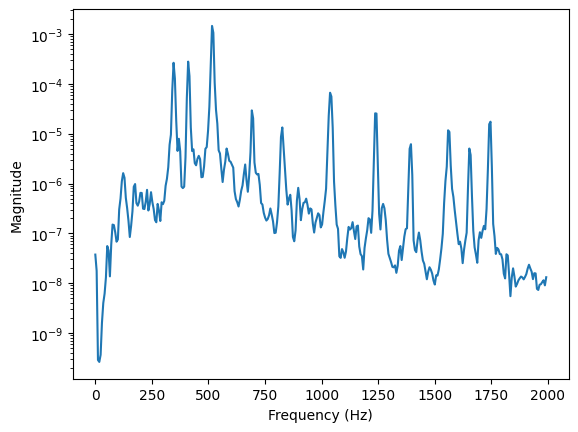

In [151]:
num_welch = len(Sxx_builtin_Welch)
plt.semilogy(f[:num_welch//12], Sxx_builtin_Welch[:num_welch//12])
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.show()

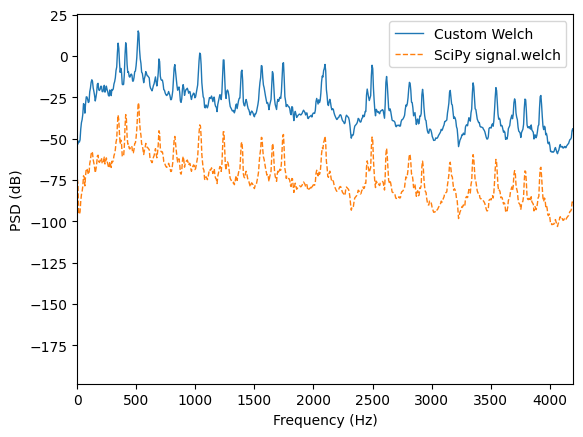

In [152]:
plt.plot(f, 10*np.log10(S_xx_Welch ), label="Custom Welch", linewidth=1)

plt.plot(f, 10*np.log10(Sxx_builtin_Welch), '--', label="SciPy signal.welch", linewidth=1)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB)")
plt.xlim(0,4200)
plt.legend()
plt.show()

# Rules
- You are NOT allowed to use the built-in “welch” function mentioned above as part of your method. However you can use it for benchmarking purposes.

- You cannot use any other audio processing or note detection software.

- You  can use standard signal processing commands such as those performing correlations, convolutions, filtering and FFTs if needed. If any doubt, you need to contact the coordinator for clarification.

- You can display intermediate results (data and plots) on screen to see how your algorithm is progressing.

- You are allowed to use AI to complete the assignment. However, you need to disclose the AI tool and how it is used to help you complete the assignment.

# Report & Submission Guidelines
You are asked to submit your Jupyter notebook with your name (**firstname_lastname**) as filename  to the Brightspace submission portal for this assignment. Your report should be all your own work.


STUDENTS MUST WORK INDEPENDENTLY. PROGRAMS WILL BE EXAMINED FOR EVIDENCE OF COPYING. COPYING OR ALLOWING YOUR WORK TO BE COPIED WILL RESULT IN ZERO MARKS BEING ALLOCATED FOR THE ASSIGNMENT.


# Grading Scheme

1. The code is efficient, which basically means you need to treat a variable as a vector or matrix when possible.

2. The code is well commented. 

3. All the plots/figures should be labelled properly, including a proper unit for each quantity shown.

4. Every step of your proposed method needs to be clearly explained. For example, if you set some parameters in your method to a specific numeric value, you also need to explain why this specific value is a good choice.

5. A good set of comments on the obtained results and make good reference to the related theory.

6. Be able to explain the difference (if any) between your implementation and other the corresponding built-in functions.


# Appendix
When a particular note is played on a musical instrument not only is the fundamental frequency (tone) generated but also higher harmonics of the fundamental, i.e., pure tones at the frequencies $2f, 3f, 4f,\ldots$ These harmonics give the instrument a richer sound. For example the DFT of a piano middle C (commonly known as “C4”) is illustrated in the following figure.
<p align="center">
    <img src="FFTC4.png">
</p>

As the frequency of C4 is ≈ 261 Hz, we can see that the DFT shown in the figure above has peaks at 261 Hz and at higher harmonics. The frequencies of a standard (i.e. 88-key) piano can be found at the following link: [https://en.wikipedia.org/wiki/Piano_key_frequencies](https://en.wikipedia.org/wiki/Piano_key_frequencies).